In [174]:
import awkward as ak
import uproot
import pandas as pd
import numpy as np

In [175]:
import vector as vec
import matplotlib.pyplot as plt

In [176]:
# test2 = uproot.open('surelyThisOne.root:Events')
test2= uproot.open('nanoAODAK1.1.root:Events')
test2.keys()

['EventAuxiliary',
 'EventProductProvenance',
 'EventSelections',
 'BranchListIndexes',
 'patJets_slimmedJets__PAT.',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.present',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJ

In [177]:
qx3 = test2.arrays(['patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_'])
qx3_df = ak.to_dataframe(qx3)
qx3_df

patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_
entry  subentry                                                                                                                 
0      0                                                        -3                                                              
       1                                                         3                                                              
1      0                                                        -3                                                              
       1                                                         3                                                              
       2                                                         3                                                              
...                                                            ...                                                              
140138 0                                                         3                                                              
       1                                                        -3                                                              
140139 0                                                         3                                                              
       1                                                        -3                                                              
       2                                                         3                                                              

[565561 rows x 1 columns]

In [178]:
sideways = test2.arrays(['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
           'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloatLabels_',
                      'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloats_'])
sideways_df = ak.to_dataframe(sideways)
sideways_df.rename(columns = {'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj':'event',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj':'run',
           'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloatLabels_':'tag_labels',
                      'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloats_':'tag_info'}, inplace = True)

sideways_df.iloc[0:20]

event     run                    tag_labels  \
entry subentry subsubentry                                                    
0     0        0            521846398  281976         QGTagger:qgLikelihood   
               1            521846398  281976                 btagDeepFlavB   
               2            521846398  281976   caloJetMap:emEnergyFraction   
               3            521846398  281976                 caloJetMap:pt   
               4            521846398  281976                 deepCSV_probb   
               5            521846398  281976                deepCSV_probbb   
               6            521846398  281976                 deepCSV_probc   
               7            521846398  281976  hfJetShowerShape:sigmaEtaEta   
               8            521846398  281976  hfJetShowerShape:sigmaPhiPhi   
               9            521846398  281976  pileupJetId:fullDiscriminant   
      1        0            521846398  281976         QGTagger:qgLikelihood   
               1            521846398  281976                 btagDeepFlavB   
               2            521846398  281976   caloJetMap:emEnergyFraction   
               3            521846398  281976                 caloJetMap:pt   
               4            521846398  281976                 deepCSV_probb   
               5            521846398  281976                deepCSV_probbb   
               6            521846398  281976                 deepCSV_probc   
               7            521846398  281976  hfJetShowerShape:sigmaEtaEta   
               8            521846398  281976  hfJetShowerShape:sigmaPhiPhi   
               9            521846398  281976  pileupJetId:fullDiscriminant   

                             tag_info  
entry subentry subsubentry             
0     0        0             0.584933  
               1             0.042529  
               2             0.379241  
               3            18.404945  
               4            -1.000000  
               5            -1.000000  
               6            -1.000000  
               7            -1.000000  
               8            -1.000000  
               9             0.384765  
      1        0            -1.000000  
               1             0.049487  
               2             0.458195  
               3            17.437084  
               4            -1.000000  
               5            -1.000000  
               6            -1.000000  
               7            -1.000000  
               8            -1.000000  
               9             0.245348

Had to do some restructuring of the btag data. entry corresponds to the event, subentry is the index of the specific jet the tag is associated with

In [179]:
label_list = ['btagDeepFlavB','deepCSV_probb','deepCSV_probbb','deepCSV_probc']
def sideways_btag(listidx):
    df = sideways_df.loc[sideways_df.tag_labels == label_list[listidx]]
    df = df.drop(['tag_labels'],axis=1)
    df.columns=df.columns.map(lambda x:x[1])
    df=df.reset_index()
    df=df.drop(['subsubentry'],axis=1)
    df.rename(columns={'v':'event','u':'run','a':label_list[listidx]},inplace=True)
    return df

dfb_df = sideways_btag(0)
bb_df = sideways_btag(1)
bbb_df = sideways_btag(2)
c_df = sideways_btag(3)

btag_df = pd.merge(dfb_df,bb_df,on=['entry','subentry','event','run'])
btag_df = pd.merge(btag_df,bbb_df,on=['entry','subentry','event','run'])
btag_df = pd.merge(btag_df,c_df,on=['entry','subentry','event','run'])
btag_df


,entry,subentry,event,run,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,0,0,521846398,281976,0.042529,-1.000000,-1.000000,-1.000000
1,0,1,521846398,281976,0.049487,-1.000000,-1.000000,-1.000000
2,0,2,521846398,281976,0.018981,0.104136,0.002120,0.119959
3,0,3,521846398,281976,0.052997,-1.000000,-1.000000,-1.000000
4,0,4,521846398,281976,0.042941,-1.000000,-1.000000,-1.000000
...,...,...,...,...,...,...,...,...
1307682,140139,2,842685715,281976,0.051491,-1.000000,-1.000000,-1.000000
1307683,140139,3,842685715,281976,0.030679,-1.000000,-1.000000,-1.000000
1307684,140139,4,842685715,281976,0.028685,-1.000000,-1.000000,-1.000000
1307685,140139,5,842685715,281976,0.060706,0.258696,0.011104,0.166426


it gets rid of some of the events and i am not sure why.

In [180]:
columns = ['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
            'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
            'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
            'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
            'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
            'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fM',
            'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
            'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
            'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
            'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM'
            ]
jet_ak = test2.arrays(columns)
jet_df = ak.to_dataframe(jet_ak)

jet_df.columns=jet_df.columns.map(lambda x:x[1])
jet_df=jet_df.reset_index()
jet_df.columns = ['entry','subentry','event','run','ak4_pt','ak4_eta','ak4_phi','ak4_mass','ak1_pt','ak1_eta','ak1_phi','ak1_mass']

jet_df

,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass
0,0,0,521846398,281976,21.287710,-3.437167,3.054484,5.071896,6.398438,-3.434614,3.055854,-1.907349e-06
1,0,1,521846398,281976,16.926594,-3.512425,0.586143,3.849146,6.210416,-2.802710,0.248688,7.977068e-02
2,0,2,521846398,281976,13.577738,-0.742079,-0.432655,3.626722,6.148438,-3.436811,0.610076,1.907349e-06
3,0,3,521846398,281976,13.526744,-3.577233,-1.321024,3.429222,5.851562,-2.757103,1.221230,6.743496e-07
4,0,4,521846398,281976,12.149314,-2.883712,0.255492,1.861137,4.371094,-0.519120,-0.521795,1.395264e-01
...,...,...,...,...,...,...,...,...,...,...,...,...
1198060,140139,2,842685715,281976,15.403499,4.074825,1.317403,4.216181,4.566406,2.429884,-0.563301,0.000000e+00
1198061,140139,3,842685715,281976,15.205867,3.331998,-1.762053,3.334666,4.187363,2.192881,-0.504609,7.565310e-02
1198062,140139,4,842685715,281976,14.680534,2.250472,-0.586167,3.230557,4.109375,3.258095,-1.832968,6.743496e-07
1198063,140139,5,842685715,281976,11.557338,1.103267,-1.303620,3.062497,4.085938,2.757653,-2.475757,-4.768372e-07


In [181]:
jet_df = pd.merge(jet_df,btag_df, on=['entry','subentry','event','run'],how='left')
jet_df

,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,0,0,521846398,281976,21.287710,-3.437167,3.054484,5.071896,6.398438,-3.434614,3.055854,-1.907349e-06,0.042529,-1.000000,-1.000000,-1.000000
1,0,1,521846398,281976,16.926594,-3.512425,0.586143,3.849146,6.210416,-2.802710,0.248688,7.977068e-02,0.049487,-1.000000,-1.000000,-1.000000
2,0,2,521846398,281976,13.577738,-0.742079,-0.432655,3.626722,6.148438,-3.436811,0.610076,1.907349e-06,0.018981,0.104136,0.002120,0.119959
3,0,3,521846398,281976,13.526744,-3.577233,-1.321024,3.429222,5.851562,-2.757103,1.221230,6.743496e-07,0.052997,-1.000000,-1.000000,-1.000000
4,0,4,521846398,281976,12.149314,-2.883712,0.255492,1.861137,4.371094,-0.519120,-0.521795,1.395264e-01,0.042941,-1.000000,-1.000000,-1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1198060,140139,2,842685715,281976,15.403499,4.074825,1.317403,4.216181,4.566406,2.429884,-0.563301,0.000000e+00,0.051491,-1.000000,-1.000000,-1.000000
1198061,140139,3,842685715,281976,15.205867,3.331998,-1.762053,3.334666,4.187363,2.192881,-0.504609,7.565310e-02,0.030679,-1.000000,-1.000000,-1.000000
1198062,140139,4,842685715,281976,14.680534,2.250472,-0.586167,3.230557,4.109375,3.258095,-1.832968,6.743496e-07,0.028685,-1.000000,-1.000000,-1.000000
1198063,140139,5,842685715,281976,11.557338,1.103267,-1.303620,3.062497,4.085938,2.757653,-2.475757,-4.768372e-07,0.060706,0.258696,0.011104,0.166426


i can't find the charge of the muons, does that matter?

In [182]:
columns = ['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_'
           ]
mu_ak = test2.arrays(['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_'
           ])
mu_df = ak.to_dataframe(mu_ak)
mu_df.columns = ['event','run','mu_pt','mu_eta','mu_phi','mu_mass','charge']
mu_df

event     run     mu_pt    mu_eta    mu_phi   mu_mass  \
entry  subentry                                                              
0      0         521846398  281976  6.304799  1.257952  2.779381  0.105700   
       1         521846398  281976  4.599942  1.114128 -2.950348  0.105700   
1      0         522613774  281976  8.468036 -1.825908  1.814388  0.105700   
       1         522613774  281976  5.833242 -2.214201  1.645171  0.105700   
       2         522613774  281976  1.067693 -1.830493 -0.094917  0.105700   
...                    ...     ...       ...       ...       ...       ...   
140138 0         842243050  281976  7.606555 -1.352662 -0.361355  0.105700   
       1         842243050  281976  4.067551 -1.883239 -0.547468  0.105700   
140139 0         842685715  281976  7.764792 -0.299779  2.716739  0.105700   
       1         842685715  281976  7.351851 -0.579240  3.012875  0.105700   
       2         842685715  281976  4.182917 -0.719864  1.503438  0.105658   

                 charge  
entry  subentry          
0      0             -3  
       1              3  
1      0             -3  
       1              3  
       2              3  
...                 ...  
140138 0              3  
       1             -3  
140139 0              3  
       1             -3  
       2              3  

[565561 rows x 7 columns]

reject when ak4 pt >> ak1 pt

In [183]:
good_events = jet_df.loc[jet_df.ak1_pt/jet_df.ak4_pt >=0.8]
good_events

,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
445,51,0,523225600,281976,67.145432,-0.634662,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731e+00,0.002138,0.021765,0.000328,0.093865
1805,199,2,521735587,281976,14.016514,2.352129,2.835542,3.517392,12.844827,0.131765,3.044132,6.457729e-01,0.045418,-1.000000,-1.000000,-1.000000
3125,351,2,522559209,281976,11.429972,-3.061151,-2.251225,2.531296,11.085938,0.649129,1.500535,1.057129e-01,0.049020,-1.000000,-1.000000,-1.000000
3275,369,0,521782488,281976,22.677647,-0.981937,2.811177,2.586818,18.924107,-0.952101,2.806896,7.231506e-01,0.011123,0.158692,0.001344,0.163244
3314,373,1,522518328,281976,35.735111,-0.513789,1.924621,8.797732,29.451611,-1.490999,-2.400406,8.224481e-02,0.583947,0.960574,0.038818,0.000479
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1197079,140009,0,842615375,281976,14.999989,1.046876,-2.330848,1.643049,12.403285,1.011445,-2.312067,1.194223e-01,0.034331,-1.000000,-1.000000,-1.000000
1197313,140038,3,841412885,281976,15.979471,-3.927645,-2.769176,3.641881,13.644053,-0.666662,-2.470667,1.121053e+00,0.053065,-1.000000,-1.000000,-1.000000
1197487,140063,0,842199066,281976,14.846371,-1.516730,-1.185635,3.839231,11.992188,1.030000,2.619415,1.057129e-01,0.069631,-1.000000,-1.000000,-1.000000
1197566,140076,1,842232350,281976,13.617375,-2.793042,-0.102353,3.083739,11.554688,0.360912,1.728861,1.057129e-01,0.043316,-1.000000,-1.000000,-1.000000


In [184]:
jet_df = jet_df.loc[jet_df.ak1_mass >1.5]

In [185]:
ak1_vec = vec.array({'pt':jet_df.ak1_pt,'eta':jet_df.ak1_eta,'phi':jet_df.ak1_phi,'mass':jet_df.ak1_mass})
ak1_energy = ak1_vec.e
ak1_energy

array([ 39.71161606,  64.56052634, 213.07445488, ..., 710.19971755,
       749.6038151 , 111.98652548], shape=(6440,))

In [186]:
ak4_vec = vec.array({'pt':jet_df.ak4_pt, 'eta':jet_df.ak4_eta,'phi':jet_df.ak4_phi,'mass':jet_df.ak4_mass})
ak4_energy = ak4_vec.e
ak4_energy

array([  79.59371221,   81.60278033,  307.5496921 , ...,  921.57588708,
       1135.02694282,  277.97077419], shape=(6440,))

In [187]:
energy_ratio = ak1_energy/ak4_energy

(array([3.933e+03, 1.569e+03, 4.720e+02, 2.360e+02, 1.010e+02, 5.500e+01,
        3.000e+01, 1.300e+01, 8.000e+00, 8.000e+00, 3.000e+00, 3.000e+00,
        3.000e+00, 0.000e+00, 3.000e+00, 1.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([  11.8002398 ,  178.83374039,  345.86724098,  512.90074157,
         679.93424216,  846.96774275, 1014.00124334, 1181.03474393,
        1348.06824451, 1515.1017451 , 1682.13524569, 1849.16874628,
        2016.20224687, 2183.23574746, 2350.26924805, 2517.30274864,
        2684.33624923, 2851.36974982, 3018.40325041, 3185.436751  ,
        3352.47025159]),
 <BarContainer object of 20 artists>)

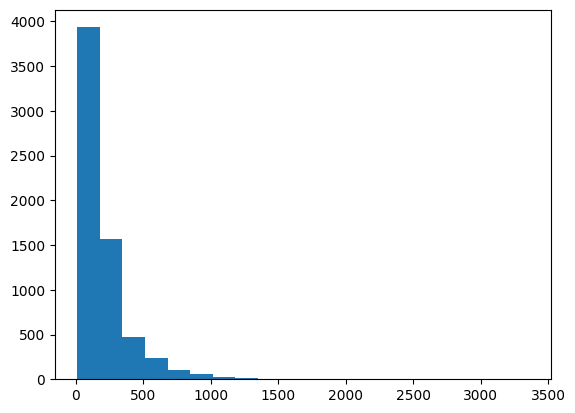

In [188]:
plt.hist(ak4_energy, bins = 20)

error can be ignored

In [189]:
jet_df.insert(loc=0, column = 'e_ratio', value=energy_ratio)

In [190]:
jet_df

,e_ratio,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
362,0.498929,42,0,521673324,281976,72.682693,-0.385794,2.002483,15.044004,37.843716,-0.310219,1.953685,1.600941,0.003872,0.025657,0.000760,0.095729
445,0.791156,51,0,523225600,281976,67.145432,-0.634662,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
570,0.692813,66,0,522947047,281976,84.892960,-1.960250,2.733319,9.774922,58.230965,-1.971090,2.725086,2.363806,0.007517,0.099091,0.003071,0.137400
704,0.517984,79,0,522660488,281976,190.178711,0.605624,-3.006094,27.540895,100.741562,0.575545,-2.966124,5.026573,0.003377,0.017986,0.000779,0.069217
705,0.318532,79,1,522660488,281976,180.527069,1.005965,0.248893,14.673553,57.598351,1.005392,0.244560,1.623364,0.877751,0.961702,0.033711,0.004573
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195928,0.362829,139873,0,841930137,281976,53.489971,-1.255259,-0.131123,8.634317,27.358246,-0.813156,3.013523,1.592657,0.004510,0.022251,0.000259,0.102222
1196362,0.130435,139930,0,841244596,281976,53.539791,-2.138533,2.707844,11.582571,28.772760,-0.294251,-0.189373,1.838911,0.020612,0.079483,0.003398,0.130367
1197370,0.770636,140046,0,842614172,281976,139.595993,2.574630,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000
1197371,0.660428,140046,1,842614172,281976,129.778000,2.858435,0.045568,5.912747,85.968475,2.855399,0.046067,2.930706,0.006023,-1.000000,-1.000000,-1.000000


(array([ 37.,  96., 147., 162., 198., 278., 386., 518., 613., 752., 767.,
        749., 621., 426., 261., 113.,  52.,  29.,  18.,  18.]),
 array([0.   , 0.055, 0.11 , 0.165, 0.22 , 0.275, 0.33 , 0.385, 0.44 ,
        0.495, 0.55 , 0.605, 0.66 , 0.715, 0.77 , 0.825, 0.88 , 0.935,
        0.99 , 1.045, 1.1  ]),
 <BarContainer object of 20 artists>)

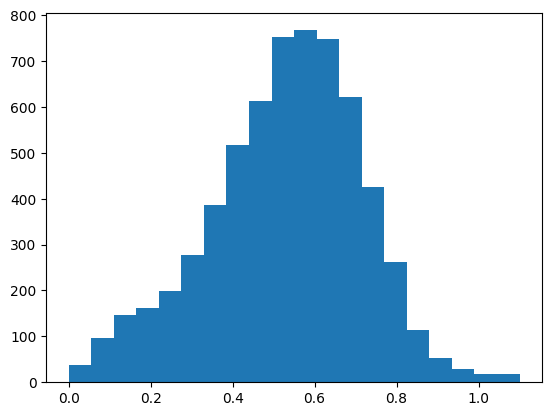

In [191]:
plt.hist(jet_df.e_ratio,bins=20, range=(0,1.1))

In [192]:
e_df = jet_df.loc[(jet_df.e_ratio>0.75)&(jet_df.e_ratio<1)]

In [193]:
e_df

,e_ratio,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
445,0.791156,51,0,523225600,281976,67.145432,-0.634662,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
1296,0.766208,146,0,521797724,281976,74.681786,0.211472,-0.875599,9.621682,57.973068,0.180757,-0.883307,2.327439,0.004905,0.024571,0.000262,0.095399
4617,0.756274,531,0,522085154,281976,172.315475,0.217581,0.091964,18.167961,130.952011,0.217546,0.081611,3.922527,0.004152,0.041813,0.001541,0.113303
8252,0.762745,930,0,522097650,281976,86.754677,-0.381408,2.622673,10.254433,66.987709,-0.361441,2.637895,2.963738,0.025302,0.060563,0.001287,0.136716
18226,0.829400,2072,0,525040960,281976,97.036652,-0.497781,-1.040632,9.834667,80.886223,-0.494380,-1.025509,3.110811,0.002363,0.010272,0.000065,0.084003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192955,0.789068,139504,0,842475926,281976,47.973335,1.190487,-2.035837,4.704500,37.931244,1.189267,-2.036986,2.086193,0.013672,0.069619,0.000581,0.205641
1193049,0.847140,139517,0,841903263,281976,114.766869,-0.488151,-0.105634,11.500332,97.451416,-0.491348,-0.105050,2.095620,0.001491,0.024955,0.000332,0.114347
1194602,0.766754,139716,0,841303859,281976,34.843887,-1.112841,2.739454,4.985102,26.764082,-1.114224,2.768162,1.693232,0.002255,0.035833,0.000202,0.077639
1194791,0.810171,139738,0,842471641,281976,80.670685,0.757241,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379


test muons from just the events that pass the jet filters

flag events with one charge combined with 2 opposite sign charges that have good jpsi mass, skip. skip events with two jpsi mass particles

In [194]:
jet_pass = e_df.event
mu_pass = mu_df.loc[mu_df.event.isin(jet_pass)]
mu_pass

event     run      mu_pt    mu_eta    mu_phi   mu_mass  \
entry  subentry                                                               
51     0         523225600  281976  11.355369  0.661126 -2.644748  0.105658   
       1         523225600  281976   6.957202  0.593670 -2.316686  0.105700   
       2         523225600  281976   4.256203  1.333030 -2.709912  0.105700   
       3         523225600  281976   3.678452  0.662462 -1.898475  0.105658   
       4         523225600  281976   0.796055  2.153830 -1.385147  0.105700   
...                    ...     ...        ...       ...       ...       ...   
139738 2         842471641  281976   0.824647  1.972735 -2.635895  0.105700   
140046 0         842614172  281976  21.589464 -0.752665  1.018305  0.105700   
       1         842614172  281976  18.700180 -0.595330  0.989635  0.105700   
       2         842614172  281976   3.571076 -0.537452  0.239294  0.105658   
       3         842614172  281976   2.066134  2.323162 -0.772168  0.105700   

                 charge  
entry  subentry          
51     0              3  
       1              3  
       2             -3  
       3              3  
       4             -3  
...                 ...  
139738 2              3  
140046 0              3  
       1             -3  
       2             -3  
       3             -3  

[2497 rows x 7 columns]

In [195]:
mu_pos = mu_pass.loc[mu_pass.charge>0]
mu_pos.columns=['event','run','mupos_pt','mupos_eta','mupos_phi','mupos_mass','charge']
mu_pos.drop(columns = 'charge', axis = 1, inplace = True)
if 'npos' not in mu_pos.columns:
    mu_pos.insert(loc=2,column='npos',value=0)
    for val in jet_pass:
        df = mu_pos.loc[mu_pos.event==val]
        mu_pos.loc[mu_pos.event==val,'npos']=len(df)
mu_neg = mu_pass.loc[mu_pass.charge<0]
mu_neg.columns=['event','run','muneg_pt','muneg_eta','muneg_phi','muneg_mass','charge']
mu_neg.drop(columns = 'charge', axis=1, inplace=True)
if 'nneg' not in mu_neg.columns:
    mu_neg.insert(loc=2,column='nneg',value=0)
    for val in jet_pass:
        df = mu_neg.loc[mu_neg.event ==val]
        mu_neg.loc[mu_neg.event==val,'nneg']=len(mu_neg.loc[mu_neg.event==val])

if 'pos_idx' not in mu_pos.columns:
    mu_pos.insert(loc=3,column='pos_idx',value=range(len(mu_pos)))
if 'neg_idx' not in mu_neg.columns:
    mu_neg.insert(loc=3,column='neg_idx',value=range(len(mu_neg)))
mu_div = pd.merge(mu_pos, mu_neg, on=['event', 'run'])
mu_div

C:\Users\avery\AppData\Local\Temp\ipykernel_29404\772749412.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mu_pos.drop(columns = 'charge', axis = 1, inplace = True)
C:\Users\avery\AppData\Local\Temp\ipykernel_29404\772749412.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mu_neg.drop(columns = 'charge', axis=1, inplace=True)


,event,run,npos,pos_idx,mupos_pt,mupos_eta,mupos_phi,mupos_mass,nneg,neg_idx,muneg_pt,muneg_eta,muneg_phi,muneg_mass
0,523225600,281976,3,0,11.355369,0.661126,-2.644748,0.105658,2,0,4.256203,1.333030,-2.709912,0.105700
1,523225600,281976,3,0,11.355369,0.661126,-2.644748,0.105658,2,1,0.796055,2.153830,-1.385147,0.105700
2,523225600,281976,3,1,6.957202,0.593670,-2.316686,0.105700,2,0,4.256203,1.333030,-2.709912,0.105700
3,523225600,281976,3,1,6.957202,0.593670,-2.316686,0.105700,2,1,0.796055,2.153830,-1.385147,0.105700
4,523225600,281976,3,2,3.678452,0.662462,-1.898475,0.105658,2,0,4.256203,1.333030,-2.709912,0.105700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2713,842471641,281976,2,1250,9.806650,1.055441,-2.094296,0.105700,1,1240,3.961611,1.838317,-1.868871,0.105700
2714,842471641,281976,2,1251,0.824647,1.972735,-2.635895,0.105700,1,1240,3.961611,1.838317,-1.868871,0.105700
2715,842614172,281976,1,1252,21.589464,-0.752665,1.018305,0.105700,3,1241,18.700180,-0.595330,0.989635,0.105700
2716,842614172,281976,1,1252,21.589464,-0.752665,1.018305,0.105700,3,1242,3.571076,-0.537452,0.239294,0.105658


In [196]:
full_df = pd.merge(mu_div,e_df,on=['event','run'])
full_df

,event,run,npos,pos_idx,mupos_pt,mupos_eta,mupos_phi,mupos_mass,nneg,neg_idx,...,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,523225600,281976,3,0,11.355369,0.661126,-2.644748,0.105658,2,0,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
1,523225600,281976,3,0,11.355369,0.661126,-2.644748,0.105658,2,1,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
2,523225600,281976,3,1,6.957202,0.593670,-2.316686,0.105700,2,0,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
3,523225600,281976,3,1,6.957202,0.593670,-2.316686,0.105700,2,1,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
4,523225600,281976,3,2,3.678452,0.662462,-1.898475,0.105658,2,0,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2825,842471641,281976,2,1250,9.806650,1.055441,-2.094296,0.105700,1,1240,...,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379
2826,842471641,281976,2,1251,0.824647,1.972735,-2.635895,0.105700,1,1240,...,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379
2827,842614172,281976,1,1252,21.589464,-0.752665,1.018305,0.105700,3,1241,...,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000
2828,842614172,281976,1,1252,21.589464,-0.752665,1.018305,0.105700,3,1242,...,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000


In [197]:
# full_df = pd.merge(mu_div,e_df,on=['event','run'])
pos_mu_vec = vec.array({"pt":full_df["mupos_pt"], "eta":full_df["mupos_eta"], "phi":full_df["mupos_phi"], "mass":full_df["mupos_mass"]})
neg_mu_vec = vec.array({"pt":full_df["muneg_pt"], "eta":full_df["muneg_eta"], "phi":full_df["muneg_phi"], "mass":full_df["muneg_mass"]})
jet_vec = vec.array({"pt":full_df['ak1_pt'], "eta":full_df["ak1_eta"], "phi":full_df["ak1_phi"], "mass":full_df["ak1_mass"]})
jpsi_vec = pos_mu_vec+neg_mu_vec
if 'jpsi_mass' not in full_df.columns:
    full_df.insert(loc=2, column='jpsi_mass',value=jpsi_vec.M)
wc_vec = jpsi_vec+jet_vec
if 'wc_mass' not in full_df.columns:
    full_df.insert(loc=3,column='wc_mass',value=wc_vec.M)
full_df

,event,run,jpsi_mass,wc_mass,npos,pos_idx,mupos_pt,mupos_eta,mupos_phi,mupos_mass,...,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,523225600,281976,4.785907,74.323981,3,0,11.355369,0.661126,-2.644748,0.105658,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
1,523225600,281976,6.064948,65.184404,3,0,11.355369,0.661126,-2.644748,0.105658,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
2,523225600,281976,4.637107,64.652823,3,1,6.957202,0.593670,-2.316686,0.105700,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
3,523225600,281976,4.579174,53.763625,3,1,6.957202,0.593670,-2.316686,0.105700,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
4,523225600,281976,4.136725,56.692479,3,2,3.678452,0.662462,-1.898475,0.105658,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2825,842471641,281976,5.202244,62.674087,2,1250,9.806650,1.055441,-2.094296,0.105700,...,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379
2826,842471641,281976,1.400324,40.362570,2,1251,0.824647,1.972735,-2.635895,0.105700,...,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379
2827,842614172,281976,3.223631,346.631710,1,1252,21.589464,-0.752665,1.018305,0.105700,...,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000
2828,842614172,281976,6.939269,279.586947,1,1252,21.589464,-0.752665,1.018305,0.105700,...,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000


Text(0.5, 1.0, 'Jpsi mass')

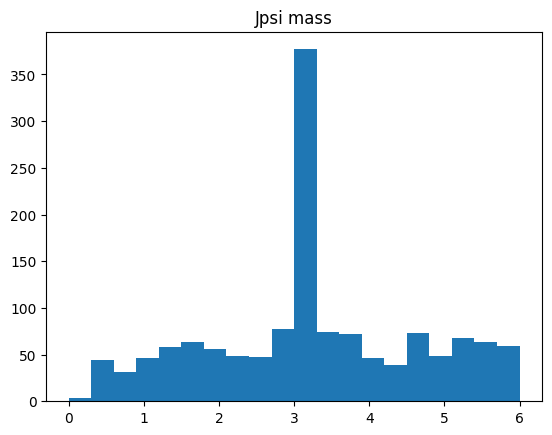

In [198]:
plt.hist(full_df.jpsi_mass,bins=20,range=(0,6))
plt.title('Jpsi mass')

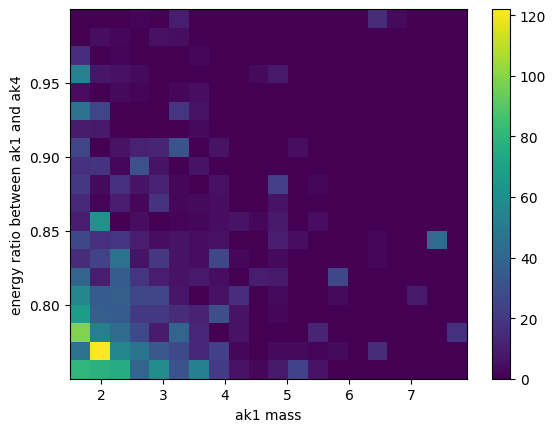

In [201]:
plt.hist2d(full_df['ak1_mass'],full_df['e_ratio'],bins=[20,20])
plt.xlabel('ak1 mass')
plt.ylabel('energy ratio between ak1 and ak4')
plt.colorbar()

jpsi mass graph, 2d plot of energy ratio to jet mass

In [203]:
if 'jpsi_tag' not in full_df.columns:
    full_df.insert(loc=2,column='jpsi_tag',value=0)
for num in jet_pass:
    df = full_df.loc[full_df.event == num]
    num_jpsi = len(df.loc[(df.jpsi_mass>2.9)&(df.jpsi_mass<3.9)])
    if num_jpsi>=1:
        full_df.loc[full_df.event==num,'jpsi_tag']+=1
    df=df.loc[(df.jpsi_mass>2.9)&(df.jpsi_mass<4.9)]
    if len(df)>len(df.pos_idx.unique()):
        full_df.loc[full_df.event==num,'jpsi_tag']+=3
    if len(df)>len(df.neg_idx.unique()):
        full_df.loc[full_df.event==num,'jpsi_tag']+=5
    if num_jpsi>2:
        full_df.loc[full_df.event==num,'jpsi_tag']+=7

full_df

,event,run,jpsi_tag,jpsi_mass,wc_mass,npos,pos_idx,mupos_pt,mupos_eta,mupos_phi,...,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,523225600,281976,9,4.785907,74.323981,3,0,11.355369,0.661126,-2.644748,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
1,523225600,281976,9,6.064948,65.184404,3,0,11.355369,0.661126,-2.644748,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
2,523225600,281976,9,4.637107,64.652823,3,1,6.957202,0.593670,-2.316686,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
3,523225600,281976,9,4.579174,53.763625,3,1,6.957202,0.593670,-2.316686,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
4,523225600,281976,9,4.136725,56.692479,3,2,3.678452,0.662462,-1.898475,...,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2825,842471641,281976,0,5.202244,62.674087,2,1250,9.806650,1.055441,-2.094296,...,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379
2826,842471641,281976,0,1.400324,40.362570,2,1251,0.824647,1.972735,-2.635895,...,0.712203,9.045307,66.076363,0.745249,0.710180,2.357952,0.003568,0.023042,0.000266,0.127379
2827,842614172,281976,1,3.223631,346.631710,1,1252,21.589464,-0.752665,1.018305,...,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000
2828,842614172,281976,1,6.939269,279.586947,1,1252,21.589464,-0.752665,1.018305,...,-2.688452,10.372820,107.405281,2.576304,-2.692926,3.578159,0.014735,-1.000000,-1.000000,-1.000000


above i am doing some tagging for the jpsis. if the tag is 9, it's really bad: there are multiple possible jpsis coming from duplicate muons of either charge (so like 4 jpsis from 2 positive and 2 negative). If it is 0, there are no jpsis in the event. If it is 1, there is one unique jpsi. If it is 4 or 6, there are multiple possible jpsis coming from at least 1 of the muons
If it is 8,10,11,12,13,or 16, there are more than 2 jpsis

In [212]:
slay_df = full_df.loc[(full_df.jpsi_tag<8)&(full_df.jpsi_mass>2.9)&(full_df.jpsi_mass<3.9)&(full_df.wc_mass<150)]
slay_df

,event,run,jpsi_tag,jpsi_mass,wc_mass,npos,pos_idx,mupos_pt,mupos_eta,mupos_phi,...,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
6,521797724,281976,1,3.137164,103.249521,1,3,8.606223,0.280879,2.252380,...,-0.875599,9.621682,57.973068,0.180757,-0.883307,2.327439,0.004905,0.024571,0.000262,0.095399
10,522085154,281976,1,3.098346,99.742392,2,5,14.151003,1.150502,1.684292,...,0.091964,18.167961,130.952011,0.217546,0.081611,3.922527,0.004152,0.041813,0.001541,0.113303
14,525040960,281976,1,3.090366,106.012134,1,7,9.507481,0.661631,2.101151,...,-1.040632,9.834667,80.886223,-0.494380,-1.025509,3.110811,0.002363,0.010272,0.000065,0.084003
15,525980491,281976,1,3.098864,5.599744,1,8,26.124069,0.102903,1.138950,...,1.126183,7.034562,42.048771,0.097773,1.140934,1.945914,0.629414,0.887966,0.006477,0.054246
16,525227702,281976,1,3.108434,72.652372,2,9,10.552052,1.774514,-2.832296,...,0.591083,6.976497,60.210575,1.523989,0.591567,1.751392,0.003290,0.040382,0.000228,0.083217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2809,842672089,281976,1,3.122988,70.113287,3,1243,30.044994,-2.266996,-2.106816,...,1.794904,18.455969,32.578857,-2.039820,1.278596,1.710067,0.013390,0.038275,0.001418,0.118418
2815,842475926,281976,1,3.045217,69.824744,1,1246,6.719282,0.047680,0.967233,...,-2.035837,4.704500,37.931244,1.189267,-2.036986,2.086193,0.013672,0.069619,0.000581,0.205641
2820,841903263,281976,6,3.088255,126.135479,2,1247,3.348399,1.762550,1.758646,...,-0.105634,11.500332,97.451416,-0.491348,-0.105050,2.095620,0.001491,0.024955,0.000332,0.114347
2822,841903263,281976,6,3.622470,121.287232,2,1248,1.777486,1.933037,1.931955,...,-0.105634,11.500332,97.451416,-0.491348,-0.105050,2.095620,0.001491,0.024955,0.000332,0.114347


(array([10., 15.,  9.,  8., 17., 16., 13., 17., 21., 17.,  9., 11.,  8.,
        10., 17.]),
 array([ 50.        ,  53.33333333,  56.66666667,  60.        ,
         63.33333333,  66.66666667,  70.        ,  73.33333333,
         76.66666667,  80.        ,  83.33333333,  86.66666667,
         90.        ,  93.33333333,  96.66666667, 100.        ]),
 <BarContainer object of 15 artists>)

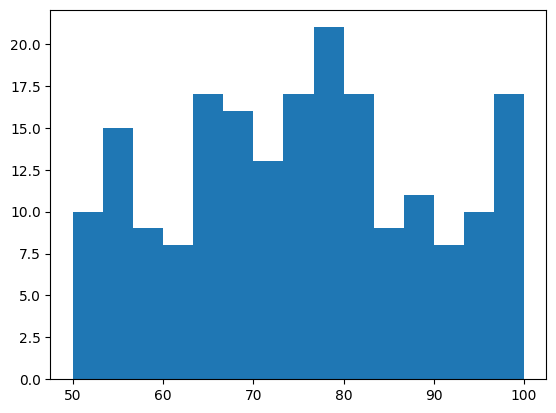

In [213]:
plt.hist(slay_df.wc_mass,bins=15,range=(50,100))

(array([ 6., 10.,  4.,  5., 11., 11.,  6.,  9., 14., 11.,  3.,  4.,  6.,
         6., 11.]),
 array([ 50.        ,  53.33333333,  56.66666667,  60.        ,
         63.33333333,  66.66666667,  70.        ,  73.33333333,
         76.66666667,  80.        ,  83.33333333,  86.66666667,
         90.        ,  93.33333333,  96.66666667, 100.        ]),
 <BarContainer object of 15 artists>)

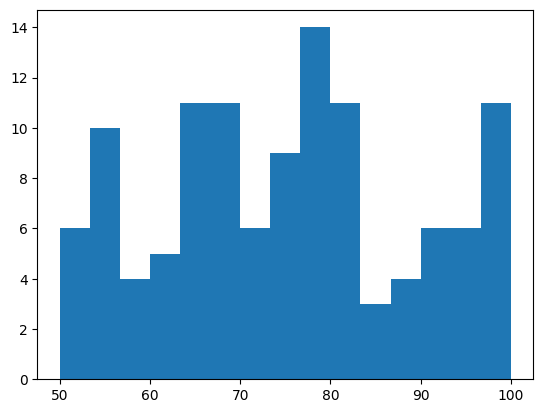

In [214]:
slayer_df = full_df.loc[(full_df.jpsi_tag==1)&(full_df.jpsi_mass>2.9)&(full_df.jpsi_mass<3.2)]
plt.hist(slayer_df.wc_mass,bins=15,range=(50,100))

(array([  0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0., 141., 261., 113.,  52.,  29.,  18.,  18.]),
 array([0.   , 0.055, 0.11 , 0.165, 0.22 , 0.275, 0.33 , 0.385, 0.44 ,
        0.495, 0.55 , 0.605, 0.66 , 0.715, 0.77 , 0.825, 0.88 , 0.935,
        0.99 , 1.045, 1.1  ]),
 <BarContainer object of 20 artists>)

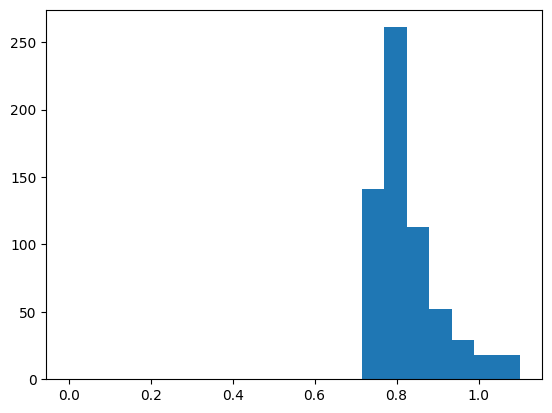

In [ ]:
plt.hist(e_df.e_ratio, bins = 20, range = (0,1.1))

(array([ 143.,  346.,  697., 1086., 1160., 1121.,  955.,  571.,  254.,
         107.]),
 array([-2.89700389, -2.30092638, -1.70484886, -1.10877135, -0.51269383,
         0.08338368,  0.67946119,  1.27553871,  1.87161622,  2.46769373,
         3.06377125]),
 <BarContainer object of 10 artists>)

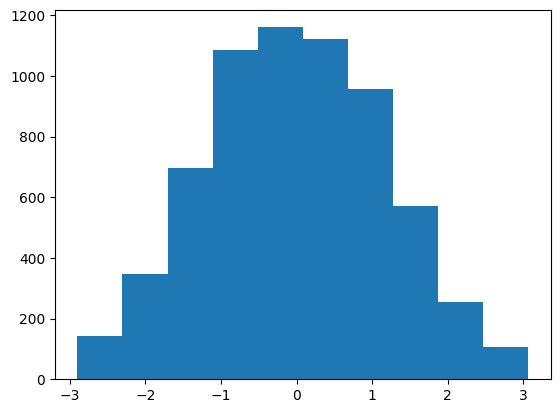

In [ ]:
plt.hist(jet_df.ak1_eta)

(array([ 49.,  65.,  85., 116., 127., 110., 121.,  68.,  52.,  38.]),
 array([-2.87026262, -2.27685924, -1.68345585, -1.09005246, -0.49664907,
         0.09675431,  0.6901577 ,  1.28356109,  1.87696447,  2.47036786,
         3.06377125]),
 <BarContainer object of 10 artists>)

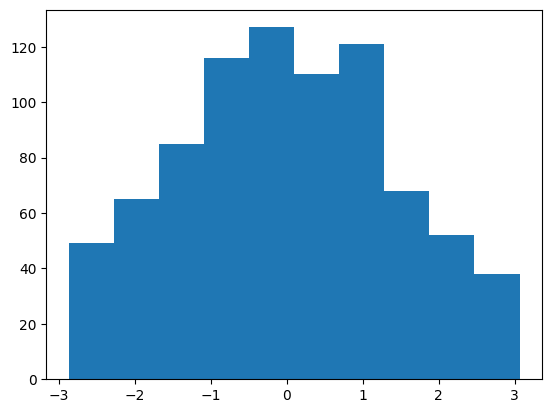

In [ ]:
plt.hist(e_df.ak1_eta)

keep energy ratio greater than 0.75
want the jet dists to match

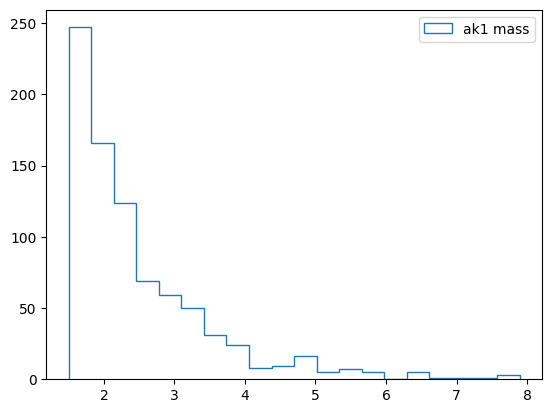

In [ ]:
plt.hist(e_df.ak1_mass, label ='ak1 mass', histtype ='step', bins = 20)
#plt.hist(e_df.ak4_mass, label = 'ak4 mass', histtype = 'step')
plt.legend()

spike around 5 is likely b jets 